# Stage 1 v2 — Initial ISBI pre-training
This rerun uses the stable spatial-softmax/KL/smooth-L1 objective and selects the primary checkpoint by validation loss. Set `ISBI_ROOT` below to the actual ISBI dataset location. The repository discovery and data-loading workflow are preserved.


In [1]:
import sys
from pathlib import Path

# Locate the repository before importing the shared .py modules. If src/ is
# stored elsewhere, replace SRC_DIR with that absolute directory.
REPO_ROOT = Path('/kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1')
for start in (Path.cwd().resolve(), Path('/kaggle/working')):
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'config.py').is_file():
            REPO_ROOT = candidate
            break
    if REPO_ROOT is not None:
        break
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate repository root containing src/config.py')
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# The dataset can be outside the repository. Config is frozen, so provide the
# path to the factory instead of trying to assign cfg.dataset_root later.
ISBI_ROOT = '/kaggle/input/datasets/pouyansajadi78/cropped-isbi-dataset/cropped_isbi_dataset/ISBI Dataset'
from config import make_stage1_initial_config
cfg = make_stage1_initial_config(dataset_root=ISBI_ROOT)
print('Repository root:', REPO_ROOT)
print('Source directory:', SRC_DIR)
print('ISBI dataset root:', cfg.dataset_root)
print(cfg)
assert cfg.decoder_filters == (1024, 512, 256)
assert cfg.epochs == 150 and cfg.warmup_epochs == 5
assert cfg.objective_version == 'v2'
assert cfg.decoding_version == 'spatial_softmax'
assert cfg.heatmap_loss == 'spatial_kl' and cfg.heatmap_loss_weight == 0.1
assert cfg.coord_loss == 'smooth_l1' and cfg.coord_loss_weight == 10.0
assert cfg.checkpoint_monitor == 'val_loss'
assert cfg.output_filename == 'best_model_fixed.weights.h5'
assert cfg.best_mre_output_filename == 'best_model_stage1_v2_best_mre.weights.h5'

Repository root: /kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1
Source directory: /kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1/src
ISBI dataset root: /kaggle/input/datasets/pouyansajadi78/cropped-isbi-dataset/cropped_isbi_dataset/ISBI Dataset
Config(stage_name='stage1_initial_v2', model_version='v2', objective_version='v2', decoding_version='spatial_softmax', seed=42, dataset_root='/kaggle/input/datasets/pouyansajadi78/cropped-isbi-dataset/cropped_isbi_dataset/ISBI Dataset', inhouse_root='/kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1/data/inhouse', ft_root='/kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1/data/inhouse', ft_images='/kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1/data/inhouse/images_v2/images_v2', ft_annotations='/kaggle/input/models/pouyansajadi78/model-sep-17-v1/tensorflow2/default/1/data/inhouse/annotations_v2/annotations_v2', num_land

In [2]:
from data import ISBIDataset, CephalometricDataLoader
from augmentation import CephalometricAugmentation
from model import build_model
from train import train
train_dataset = ISBIDataset(cfg.dataset_root, cfg, mode='train')
val_dataset = ISBIDataset(cfg.dataset_root, cfg, mode='test')
train_loader = CephalometricDataLoader(train_dataset, cfg, shuffle=True, augmentation=CephalometricAugmentation(cfg))
val_loader = CephalometricDataLoader(val_dataset, cfg, shuffle=False, augmentation=None)
model, encoder_layer_names = build_model(cfg)
model.summary()

I0000 00:00:1789676326.471579      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789676326.477627      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "CephalometricNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 416,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 518, 422,  │          0 │ input_image[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 256, 208,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 256, 208,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 256, 208,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 258, 210,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 128, 104,  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 128, 104,  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 128, 104,  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 128, 104,  │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 128, 104,  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 128, 104,  │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 128, 104,  │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 128, 104,  │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 128, 104,  │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 128, 104,  │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 128, 104,  │      1,024 │ conv2_block1_3_c

 Total params: 73,288,915 (279.58 MB)

 Trainable params: 73,235,795 (279.37 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [3]:
# Keep online training augmented, but evaluate the same training cohort without
# augmentation so its curve is directly comparable with validation.
train_eval_dataset = ISBIDataset(cfg.dataset_root, cfg, mode='train')
train_eval_loader = CephalometricDataLoader(
    train_eval_dataset,
    cfg,
    shuffle=False,
    augmentation=None,
)

history = train(
    cfg,
    train_loader=train_loader,
    train_eval_loader=train_eval_loader,
    val_loader=val_loader,
    model=model,
    encoder_layer_names=encoder_layer_names,
)
history_path = Path(history['history_path'])
print('History keys:', list(history))
print('Saved history:', history_path)
print('Primary best-loss checkpoint:', history['checkpoint_paths']['primary'])
print('Secondary best-MRE checkpoint:', history['checkpoint_paths']['best_mre'])


Parameters — trainable: 49,701,203; non-trainable: 23,587,712; total: 73,288,915
Epoch 0 stage1_initial_v2 baseline — val loss: 2.24289; val MRE: 57.78 mm

Epoch 1/150
----------------------------------------
  Train online — loss 1.44505 | MRE 34.41 mm
  Train eval   — loss 0.97992 | MRE 20.52 mm
  Validation   — loss 1.00454 | MRE 21.25 mm | SDR@2 0.8% | SDR@2.5 1.4% | SDR@3 1.9% | SDR@4 3.6%
  New best MRE 21.252 mm — saved /kaggle/working/best_model_stage1_v2_best_mre.weights.h5
  New best val_loss 1.00454 — saved /kaggle/working/best_model_fixed.weights.h5

Epoch 2/150
----------------------------------------
  Train online — loss 0.84516 | MRE 17.06 mm
  Train eval   — loss 0.61593 | MRE 10.72 mm
  Validation   — loss 0.62617 | MRE 11.07 mm | SDR@2 3.2% | SDR@2.5 5.0% | SDR@3 7.3% | SDR@4 12.6%
  New best MRE 11.069 mm — saved /kaggle/working/best_model_stage1_v2_best_mre.weights.h5
  New best val_loss 0.626171 — saved /kaggle/working/best_model_fixed.weights.h5

Epoch 3/150
----

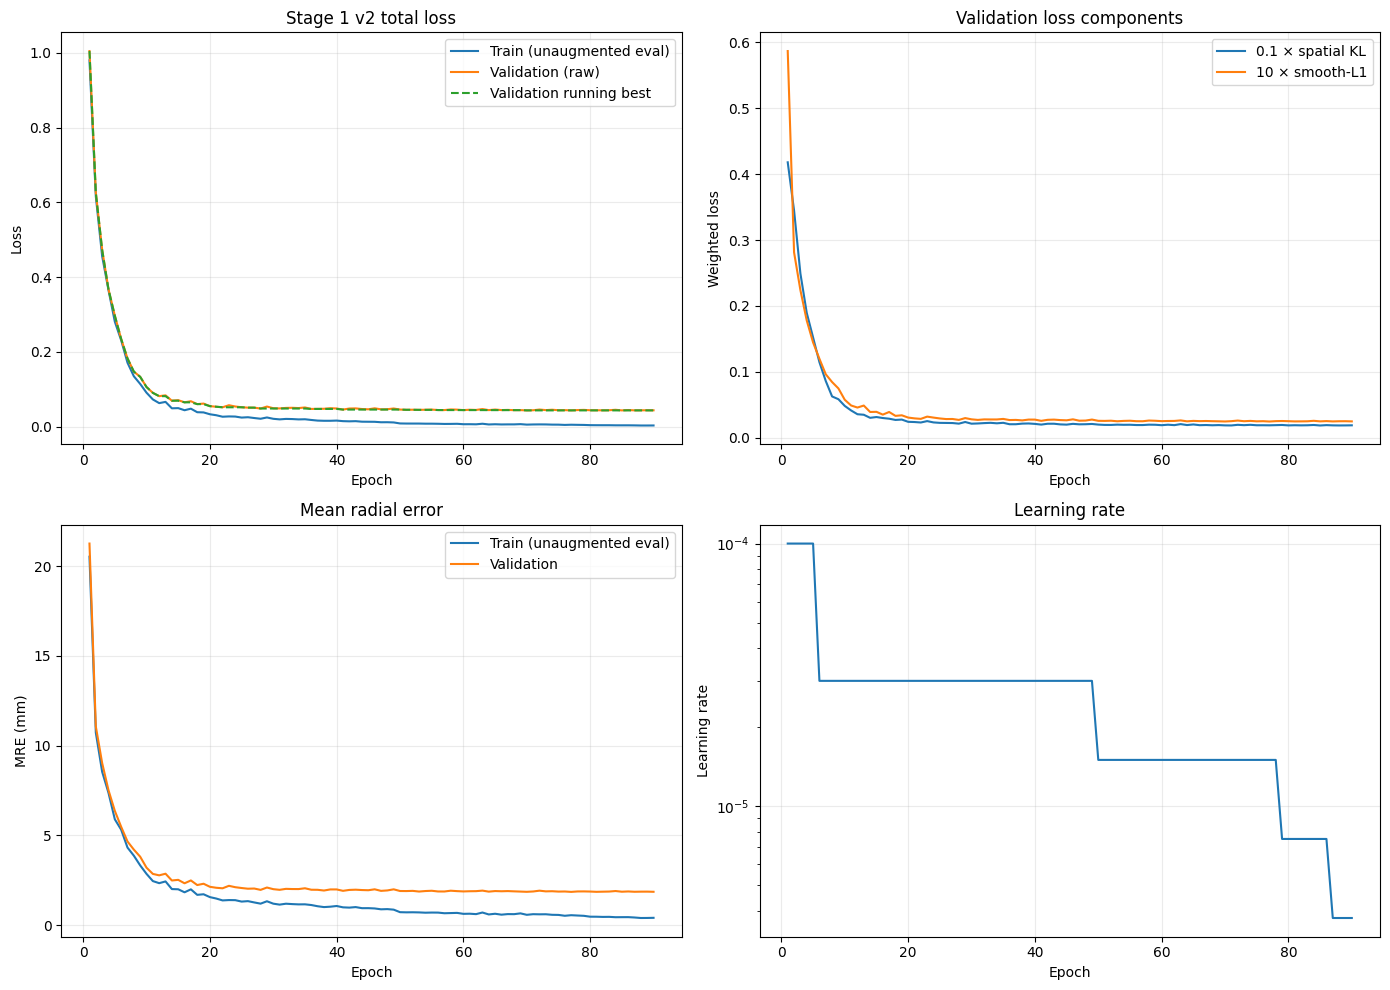

In [4]:
import matplotlib.pyplot as plt

epochs = history['epoch']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(epochs, history['train_eval_loss'], label='Train (unaugmented eval)')
axes[0, 0].plot(epochs, history['val_loss'], label='Validation (raw)')
axes[0, 0].plot(epochs, history['val_loss_running_best'], '--', label='Validation running best')
axes[0, 0].set(title='Stage 1 v2 total loss', xlabel='Epoch', ylabel='Loss')
axes[0, 0].legend()

axes[0, 1].plot(epochs, history['val_weighted_hm_loss'], label='0.1 × spatial KL')
axes[0, 1].plot(epochs, history['val_weighted_coord_loss'], label='10 × smooth-L1')
axes[0, 1].set(title='Validation loss components', xlabel='Epoch', ylabel='Weighted loss')
axes[0, 1].legend()

axes[1, 0].plot(epochs, history['train_eval_mre'], label='Train (unaugmented eval)')
axes[1, 0].plot(epochs, history['val_mre'], label='Validation')
axes[1, 0].set(title='Mean radial error', xlabel='Epoch', ylabel='MRE (mm)')
axes[1, 0].legend()

axes[1, 1].plot(epochs, history['learning_rate'])
axes[1, 1].set(title='Learning rate', xlabel='Epoch', ylabel='Learning rate')
axes[1, 1].set_yscale('log')

for axis in axes.flat:
    axis.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [5]:
restored = history.get('restored_final_validation') or {}
print(f"Best validation loss: {history['best_loss_value']:.6f} at epoch {history['best_loss_epoch']}")
print(f"Best validation MRE:  {history['best_mre_value']:.3f} mm at epoch {history['best_mre_epoch']}")
print(f"Stopped at epoch {history['stopped_epoch']}: {history['stop_reason']}")
print('Restored checkpoint:', history.get('restored_checkpoint'))
if restored:
    print(f"Restored validation loss: {restored['loss']:.6f}")
    print(f"Restored validation MRE:  {restored['mre']:.3f} mm")


Best validation loss: 0.043736 at epoch 85
Best validation MRE:  1.860 mm at epoch 77
Stopped at epoch 90: early_stopping_val_loss
Restored checkpoint: /kaggle/working/best_model_fixed.weights.h5
Restored validation loss: 0.043736
Restored validation MRE:  1.870 mm
